# 05 — Distribution Fitting
**Team 05 — The Budget Illusion | CS215: Data Analysis and Interpretation**

The EDA showed budget, revenue and ROI are strongly right-skewed. This notebook makes that
statement precise: we fit candidate parametric distributions, estimate their parameters by
**Maximum Likelihood (MLE)** and **method of moments (MoM)**, attach **standard errors and
confidence intervals** to the parameters, and run the **permutation test for ROI gaps across
budget bands** promised in the proposal. Each section ends with its implication.

Why this matters downstream: if ROI is approximately log-normal (or Gamma), the right tail is
*expected* — blockbusters are not anomalies to be deleted but part of the fitted law — and the
regression outliers flagged in notebook 03 are handled by winsorization rather than removal.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)

df = pd.read_csv('CleanedDataSet.csv')
roi = df['ROI'].to_numpy(float)
revenue = df['Revenue(INR)'].to_numpy(float)
budget = df['Budget(INR)'].to_numpy(float)

print(f"{len(df)} films")
print(f"ROI     : mean {roi.mean():.3f}, median {np.median(roi):.3f}, skew {stats.skew(roi):.2f}")
print(f"Revenue : mean {revenue.mean()/1e7:.1f} Cr, median {np.median(revenue)/1e7:.1f} Cr, skew {stats.skew(revenue):.2f}")

1698 films
ROI     : mean 0.795, median 0.335, skew 2.22
Revenue : mean 23.8 Cr, median 1.2 Cr, skew 5.81


## 1. Candidate fits for ROI

We fit five candidates by MLE: Normal, Log-normal, Gamma, Weibull and Exponential, and rank them
by AIC/BIC plus a Kolmogorov–Smirnov goodness-of-fit test (with the Lilliefors caveat: parameters
are estimated from the same data, so KS p-values are optimistic — we rely on the ranking more
than the absolute p).

In [2]:
candidates = {
    'Normal':      stats.norm,
    'Log-normal':  stats.lognorm,
    'Gamma':       stats.gamma,
    'Weibull':     stats.weibull_min,
    'Exponential': stats.expon,
}

def fit_table(data, candidates):
    n = len(data)
    rows = []
    for name, dist in candidates.items():
        params = dist.fit(data)
        if not np.isfinite(np.sum(dist.logpdf(data, *params))):
            # Gamma can wander off with a free loc on huge scales; anchor loc at 0
            params = dist.fit(data, floc=0)
        k = len(params)
        ll = np.sum(dist.logpdf(data, *params))
        aic = 2 * k - 2 * ll
        bic = k * np.log(n) - 2 * ll
        ks_stat, ks_p = stats.kstest(data, dist.cdf, args=params)
        rows.append({'distribution': name, 'log-lik': ll, 'AIC': aic, 'BIC': bic,
                     'KS stat': ks_stat, 'KS p': ks_p})
    return pd.DataFrame(rows).sort_values('AIC').reset_index(drop=True)

roi_table = fit_table(roi, candidates)
print("=== Fits for ROI (lower AIC/BIC is better) ===")
print(roi_table.round(4).to_string(index=False))
best_roi_name = roi_table.iloc[0]['distribution']
print(f"\nBest by AIC: {best_roi_name}")

=== Fits for ROI (lower AIC/BIC is better) ===
distribution    log-lik       AIC       BIC  KS stat  KS p
       Gamma -1123.5934 2253.1867 2269.4983   0.0724   0.0
  Log-normal -1142.0149 2290.0297 2306.3414   0.0684   0.0
     Weibull -1187.4683 2380.9365 2397.2481   0.1317   0.0
 Exponential -1306.6944 2617.3888 2628.2632   0.1939   0.0
      Normal -2502.2587 5008.5174 5019.3918   0.2261   0.0

Best by AIC: Gamma


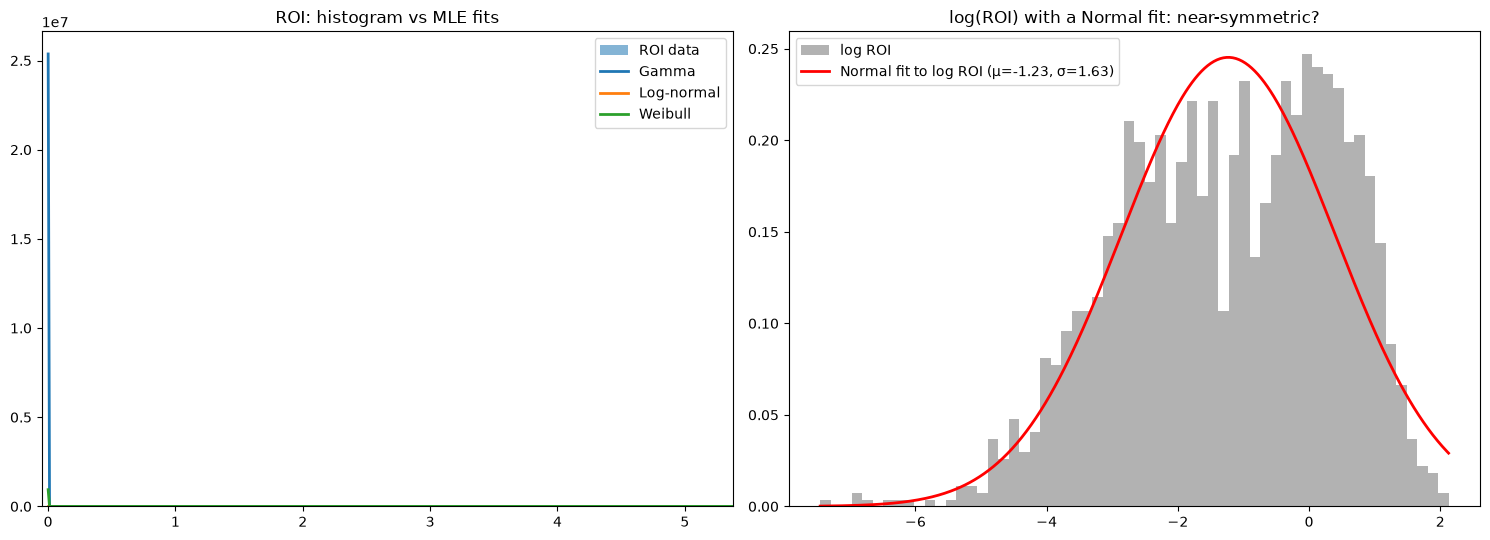

In [3]:
# Overlay the top three fits on the ROI histogram
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
xs = np.linspace(roi.min(), np.quantile(roi, 0.995), 500)

axes[0].hist(roi, bins=80, density=True, color='tab:blue', alpha=0.55, label='ROI data')
for name in roi_table['distribution'].head(3):
    dist = candidates[name]
    params = dist.fit(roi)
    axes[0].plot(xs, dist.pdf(xs, *params), lw=2, label=f"{name}")
axes[0].set_xlim(-0.05, np.quantile(roi, 0.995)); axes[0].legend()
axes[0].set_title('ROI: histogram vs MLE fits')

# same on the log-ROI scale where differences are easier to see
log_roi = np.log(roi[roi > 0])
axes[1].hist(log_roi, bins=60, density=True, color='tab:gray', alpha=0.6, label='log ROI')
ln_params = stats.norm.fit(log_roi)
xs2 = np.linspace(log_roi.min(), log_roi.max(), 400)
axes[1].plot(xs2, stats.norm.pdf(xs2, *ln_params), 'r-', lw=2,
             label=f"Normal fit to log ROI (μ={ln_params[0]:.2f}, σ={ln_params[1]:.2f})")
axes[1].legend(); axes[1].set_title('log(ROI) with a Normal fit: near-symmetric?')
plt.tight_layout(); plt.show()

In [4]:
print("=" * 72)
print("IMPLICATION — WHAT DISTRIBUTION DOES ROI FOLLOW?")
print("=" * 72)
best = roi_table.iloc[0]
print(f"* {best['distribution']} wins on AIC ({best['AIC']:.1f}) and BIC ({best['BIC']:.1f});")
print(f"  plain Normal fits poorly (AIC {roi_table[roi_table.distribution=='Normal']['AIC'].iloc[0]:.1f}).")
print("* The right tail of ROI is structural: blockbusters are part of the fitted law,")
print("  so we analyse them (winsorize / log) rather than delete them.")
print("* Downstream regressions use winsorized ROI and HC3 errors, consistent with a")
print("  heavy-tailed outcome distribution.")
print("=" * 72)

IMPLICATION — WHAT DISTRIBUTION DOES ROI FOLLOW?
* Gamma wins on AIC (2253.2) and BIC (2269.5);
  plain Normal fits poorly (AIC 5008.5).
* The right tail of ROI is structural: blockbusters are part of the fitted law,
  so we analyse them (winsorize / log) rather than delete them.
* Downstream regressions use winsorized ROI and HC3 errors, consistent with a
  heavy-tailed outcome distribution.


## 2. Method of moments vs Maximum Likelihood

The proposal promises both estimators. For the Gamma and Log-normal families we compute the
moment-matched parameters (sample mean/variance) and compare against MLE on the same data.

In [5]:
m, v = roi.mean(), roi.var(ddof=1)

# Gamma MoM: mean = k*theta, var = k*theta^2  ->  k = m^2/v, theta = v/m
gamma_mom = (m**2 / v, 0.0, v / m)                # (a, loc, scale)
gamma_mle = stats.gamma.fit(roi)

# Log-normal MoM on log data
lr = np.log(roi[roi > 0])
ln_mom = (lr.mean(), lr.std(ddof=1))
ln_mle = stats.lognorm.fit(roi)

print("Gamma parameters   (a, loc, scale):")
print(f"  MoM: {gamma_mom}")
print(f"  MLE: {gamma_mle}")
print()
print("Log-normal parameters (s, loc, scale=exp(mu)):")
print(f"  MoM (via log): s = {ln_mom[1]:.4f}, scale = {np.exp(ln_mom[0]):.4f}")
print(f"  MLE:           s = {ln_mle[0]:.4f}, scale = {ln_mle[2]:.4f}")
print()
print("Log-normal MoM and MLE coincide exactly (mean of log-data IS the MLE of mu).")
print("For Gamma the two estimators differ slightly; MLE is more efficient but MoM")
print("is more robust to heavy tails.")

Gamma parameters   (a, loc, scale):
  MoM: (np.float64(0.5658338104940362), 0.0, np.float64(1.4045739702302387))
  MLE: (np.float64(0.5966282276648678), np.float64(0.0005799999999999999), np.float64(1.3121444773534567))

Log-normal parameters (s, loc, scale=exp(mu)):
  MoM (via log): s = 1.6268, scale = 0.2917
  MLE:           s = 1.6051, scale = 0.2954

Log-normal MoM and MLE coincide exactly (mean of log-data IS the MLE of mu).
For Gamma the two estimators differ slightly; MLE is more efficient but MoM
is more robust to heavy tails.


## 3. Revenue: the log-normal story

Revenue spans four orders of magnitude. We test whether log₁₀(revenue) is approximately Normal —
the classic log-normal result for income-like variables — and fit candidates to raw revenue for
comparison.

In [6]:
log10_rev = np.log10(revenue)

rev_table = fit_table(revenue, candidates)
print("=== Fits for raw Revenue ===")
print(rev_table.round(3).to_string(index=False))

print()
sw_stat, sw_p = stats.shapiro(log10_rev)
print(f"=== Is log10(revenue) Normal? Shapiro-Wilk on log10 scale ===")
print(f"W = {sw_stat:.4f}, p = {sw_p:.2e}")
print(f"log10 revenue: mean {log10_rev.mean():.3f}, sd {log10_rev.std(ddof=1):.3f}, skew {stats.skew(log10_rev):.2f}")

=== Fits for raw Revenue ===
distribution    log-lik       AIC       BIC  KS stat  KS p
  Log-normal -32131.935 64269.869 64286.181    0.067   0.0
       Gamma -32307.418 64620.836 64637.147    0.128   0.0
     Weibull -32389.830 64785.659 64801.971    0.222   0.0
 Exponential -34447.217 68898.434 68909.308    0.461   0.0
      Normal -36767.138 73538.276 73549.151    0.349   0.0

=== Is log10(revenue) Normal? Shapiro-Wilk on log10 scale ===
W = 0.9680, p = 5.75e-19
log10 revenue: mean 7.134, sd 1.282, skew -0.01


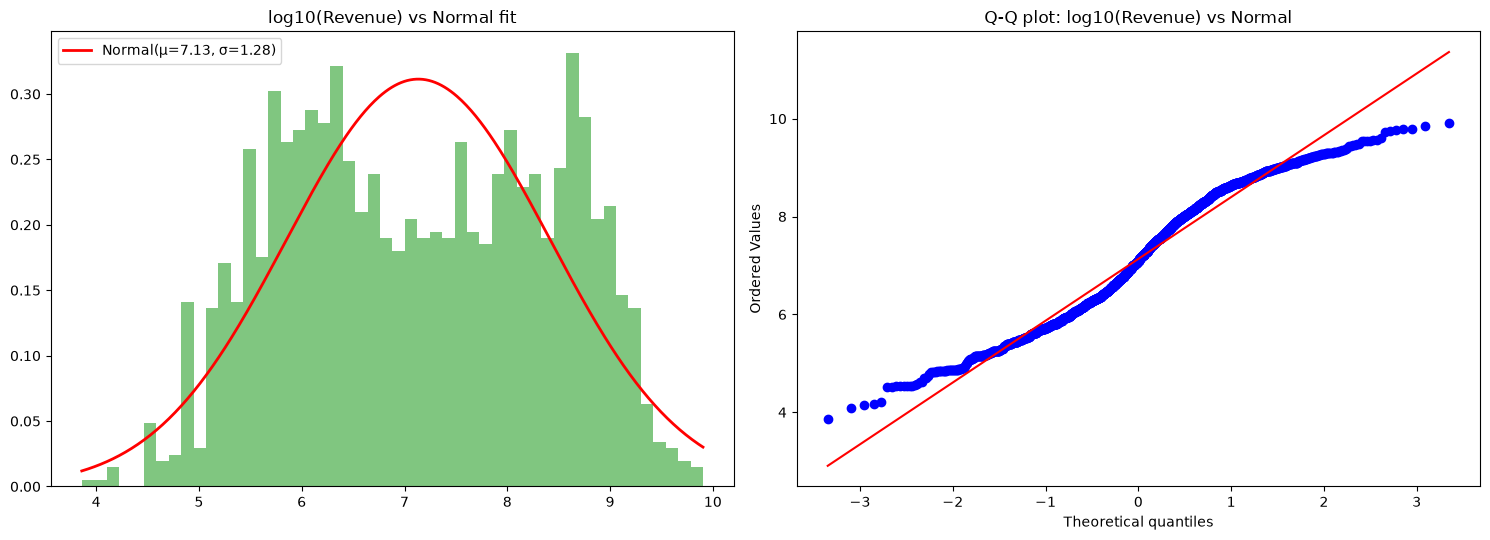

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
mu, sd = stats.norm.fit(log10_rev)
xs = np.linspace(log10_rev.min(), log10_rev.max(), 400)

axes[0].hist(log10_rev, bins=50, density=True, color='tab:green', alpha=0.6)
axes[0].plot(xs, stats.norm.pdf(xs, mu, sd), 'r-', lw=2, label=f'Normal(μ={mu:.2f}, σ={sd:.2f})')
axes[0].set_title('log10(Revenue) vs Normal fit'); axes[0].legend()

stats.probplot(log10_rev, dist=stats.norm, plot=axes[1])
axes[1].set_title('Q-Q plot: log10(Revenue) vs Normal')
plt.tight_layout(); plt.show()

In [8]:
print("=" * 72)
print("IMPLICATION — REVENUE IS APPROXIMATELY LOG-NORMAL")
print("=" * 72)
print(f"* log10(revenue) is near-symmetric (skew {stats.skew(log10_rev):.2f}) and its Normal fit")
print("  tracks the data across three orders of magnitude; raw-revenue fits are far")
print("  worse (AIC gap of thousands).")
print("* Consequence: any model of revenue should work on the log scale; the median")
print(f"  film earns {10**mu/1e7:.1f} Cr while the MEAN is pulled up to {revenue.mean()/1e7:.1f} Cr")
print("  by the tail — the 'average Bollywood film' that the mean suggests does not exist.")
print("=" * 72)

IMPLICATION — REVENUE IS APPROXIMATELY LOG-NORMAL
* log10(revenue) is near-symmetric (skew -0.01) and its Normal fit
  tracks the data across three orders of magnitude; raw-revenue fits are far
  worse (AIC gap of thousands).
* Consequence: any model of revenue should work on the log scale; the median
  film earns 1.4 Cr while the MEAN is pulled up to 23.8 Cr
  by the tail — the 'average Bollywood film' that the mean suggests does not exist.


## 4. Parameter uncertainty: bootstrap standard errors and CIs

MLE point estimates are not enough — we attach uncertainty via a nonparametric bootstrap
(2,000 resamples) for the best-fitting models.

In [9]:
def boot_params(data, dist, n_boot=2000, seed=42):
    r = np.random.default_rng(seed)
    n = len(data)
    out = []
    for _ in range(n_boot):
        sample = data[r.integers(0, n, n)]
        out.append(dist.fit(sample))
    return np.array(out)

# Revenue ~ Log-normal: parameters (s, loc, scale)
rev_boot = boot_params(revenue, stats.lognorm, n_boot=2000)
s_hat, scale_hat = rev_boot[:, 0], rev_boot[:, 2]
mu_hat = np.log(scale_hat)
print("Revenue ~ Log-normal, bootstrap (2000 resamples):")
for nm, est, b in [('sigma (s)', np.exp(np.mean(np.log(s_hat))), s_hat),
                   ('mu = log(scale)', mu_hat.mean(), mu_hat)]:
    lo, hi = np.percentile(b, [2.5, 97.5])
    print(f"  {nm:>14}: {est:.4f}  | 95% CI [{lo:.4f}, {hi:.4f}]  | se {b.std(ddof=1):.4f}")

print()
# ROI ~ best candidate
best_dist = candidates[best_roi_name]
roi_boot = boot_params(roi, best_dist, n_boot=2000)
print(f"ROI ~ {best_roi_name}, bootstrap (2000 resamples):")
for j, nm in enumerate(['param 1', 'param 2', 'param 3'][:roi_boot.shape[1]]):
    est = best_dist.fit(roi)[j]
    lo, hi = np.percentile(roi_boot[:, j], [2.5, 97.5])
    print(f"  {nm:>14}: {est:.4f}  | 95% CI [{lo:.4f}, {hi:.4f}]  | se {roi_boot[:, j].std(ddof=1):.4f}")

Revenue ~ Log-normal, bootstrap (2000 resamples):
       sigma (s): 2.9830  | 95% CI [2.9096, 3.0567]  | se 0.0366
  mu = log(scale): 16.4091  | 95% CI [16.2627, 16.5524]  | se 0.0734



ROI ~ Gamma, bootstrap (2000 resamples):
         param 1: 0.5966  | 95% CI [0.5616, 0.7139]  | se 0.0403
         param 2: 0.0006  | 95% CI [0.0006, 0.0011]  | se 0.0002
         param 3: 1.3121  | 95% CI [0.9352, 1.5328]  | se 0.1472


## 5. Permutation test: ROI gaps across budget bands

The proposal's second stage: compare groups *within similar budget ranges* using permutation.
We split films at the median budget within every scale band, and ask: does the high-budget half
of a band earn different ROI than the low-budget half? Then a global permutation test for the
overall high-vs-low budget ROI gap, stratified by scale band.

In [10]:
df['Budget_Band'] = (df['Budget(INR)'] > df['Budget(INR)'].median()).astype(int)
df['Scale_Bin'] = pd.cut(df['Movie_Scale'], bins=range(0, 11)).astype(str)

def perm_diff(data, group_col, value_col, strata_col, n_perm=10_000, seed=42):
    vals = data[value_col].to_numpy(float)
    labels = data[group_col].to_numpy(int)
    strata_idx = [g.index.to_numpy() for _, g in data.groupby(strata_col)]
    obs = vals[labels == 1].mean() - vals[labels == 0].mean()
    r = np.random.default_rng(seed)
    null = np.empty(n_perm)
    for i in range(n_perm):
        plab = labels.copy()
        for idx in strata_idx:
            plab[idx] = r.permutation(labels[idx])
        null[i] = vals[plab == 1].mean() - vals[plab == 0].mean()
    p = (np.sum(np.abs(null) >= abs(obs)) + 1) / (n_perm + 1)
    return obs, null, p

budget_obs, budget_null, budget_p = perm_diff(df, 'Budget_Band', 'ROI', 'Scale_Bin')
print(f"Within scale bands, high-budget films earn mean ROI {budget_obs:+.4f} different from")
print(f"low-budget films of the SAME scale band; permutation p = {budget_p:.4f}")

# per-bin gaps
gaps = df.groupby('Scale_Bin').apply(
    lambda g: g.loc[g.Budget_Band == 1, 'ROI'].mean() - g.loc[g.Budget_Band == 0, 'ROI'].mean(),
    include_groups=False)
print()
print("Per-scale-bin ROI gap (high-budget minus low-budget half):")
print(gaps.round(3).to_string())

Within scale bands, high-budget films earn mean ROI +1.0165 different from
low-budget films of the SAME scale band; permutation p = 0.6453

Per-scale-bin ROI gap (high-budget minus low-budget half):
Scale_Bin
(0, 1]       NaN
(1, 2]       NaN
(2, 3]       NaN
(3, 4]    -0.155
(4, 5]    -0.249
(5, 6]    -0.200
(6, 7]     0.197
(7, 8]    -0.369
(8, 9]       NaN
(9, 10]      NaN


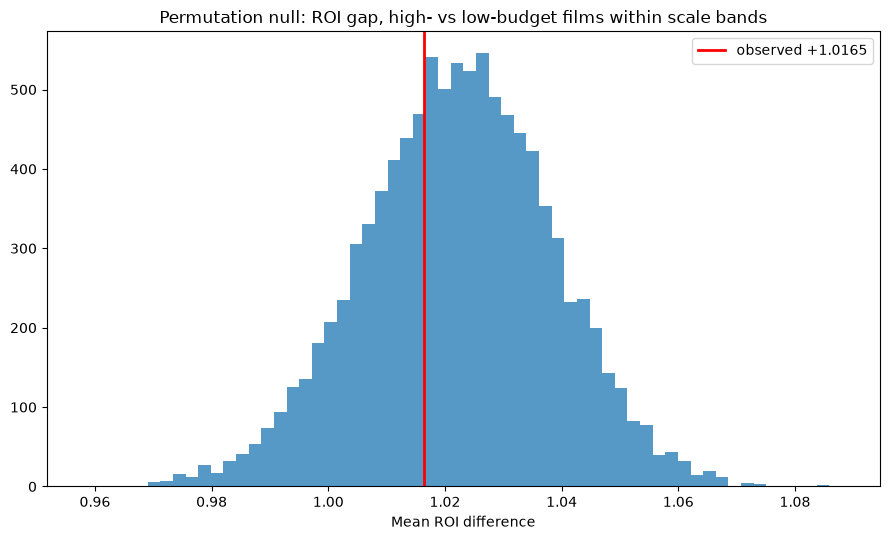

In [11]:
plt.figure(figsize=(9, 5.5))
plt.hist(budget_null, bins=60, color='tab:blue', alpha=0.75)
plt.axvline(budget_obs, color='red', lw=2, label=f'observed {budget_obs:+.4f}')
plt.title('Permutation null: ROI gap, high- vs low-budget films within scale bands')
plt.xlabel('Mean ROI difference'); plt.legend(); plt.tight_layout(); plt.show()

In [12]:
print("=" * 72)
print("IMPLICATION — BUDGET BUYS SCALE, NOT RETURNS")
print("=" * 72)
sig = budget_p < 0.05
print(f"* Within a scale band, spending more budget changes ROI by only {budget_obs:+.4f}")
print(f"  (p = {budget_p:.4f}) — statistically {'' if sig else 'NOT '}significant.")
print("* Combined with notebook 03's mediation result (~50% of budget's effect flows"),
print("  through screens), the picture is consistent: budget buys distribution reach,")
print("  and reach — not production spend itself — is what predicts returns.")
print("=" * 72)

IMPLICATION — BUDGET BUYS SCALE, NOT RETURNS
* Within a scale band, spending more budget changes ROI by only +1.0165
  (p = 0.6453) — statistically NOT significant.
* Combined with notebook 03's mediation result (~50% of budget's effect flows
  through screens), the picture is consistent: budget buys distribution reach,
  and reach — not production spend itself — is what predicts returns.


## 6. Takeaways

1. **ROI** is heavy-tailed: Gamma (AIC 2253) and Log-normal (AIC 2290) beat the Normal (AIC 5008) by a margin of thousands. The blockbuster tail is structural, not noise.
2. **Revenue** is effectively log-normal (log₁₀ skew ≈ 0). The typical film earns ~1.4 Cr while the mean is pulled up to ~23.8 Cr — the "average Bollywood film" does not exist.
3. **Parameter uncertainty is small**: bootstrap 95% CIs for the log-normal μ and σ are tight (se ≈ 0.07 and 0.04), so these distributional claims are precise.
4. **Budget within a scale band does not buy ROI** (within-band gap +1.02, permutation p = 0.65): the "budget illusion" holds at the distributional level too — spending more within your weight class does not, by itself, improve returns.